1(a)

In [29]:
import pandas as pd
from sklearn.model_selection import train_test_split

file_path = "../data/Homework 7 Data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv"
df = pd.read_csv(file_path)

# Select the 22 MFCC features and the three labels
X = df.filter(like="MFCCs_")
y = df[["Family", "Genus", "Species"]]

# Randomly assign 70% of the samples to the training set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.7, random_state=42
)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (5036, 22) (5036, 3)
Test set: (2159, 22) (2159, 3)


1(b)i

In [30]:
import numpy as np

def evaluate_multilabel(y_true, y_pred):
    # Rows are samples; columns are Family, Genus, and Species.
    correct = np.asarray(y_true) == np.asarray(y_pred)

    return {
        "Exact Match": correct.all(axis=1).mean(),
        "Hamming Score": correct.mean(),
        "Hamming Loss": (~correct).mean()
    }

1(b)ii

In [31]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

param_grid = {
    "estimator__C": [1, 10, 100],
    "estimator__gamma": [0.5, 2, 8]
}

y_pred_rbf = pd.DataFrame(index=y_test.index)
results = []

for label in y_train.columns:
    model = OneVsRestClassifier(SVC(kernel="rbf"))
    search = GridSearchCV(model, param_grid, cv=cv, scoring="accuracy", n_jobs=4)
    search.fit(X_train, y_train[label])

    y_pred_rbf[label] = search.predict(X_test)
    results.append({
        "Label": label,
        "Best C": search.best_params_["estimator__C"],
        "Best gamma": search.best_params_["estimator__gamma"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (y_pred_rbf[label] == y_test[label]).mean()
    })

display(pd.DataFrame(results).round(4))

# Evaluate all three labels together using the function from 1(b)(i)
rbf_metrics = evaluate_multilabel(y_test, y_pred_rbf)
display(pd.DataFrame([rbf_metrics], index=["RBF SVM"]).round(4))

,Label,Best C,Best gamma,CV accuracy,Test accuracy
0,Family,100,2,0.9927,0.9954
1,Genus,10,2,0.9915,0.9907
2,Species,100,2,0.9911,0.9912


,Exact Match,Hamming Score,Hamming Loss
RBF SVM,0.9889,0.9924,0.0076


1(b)iii

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

l1_model = Pipeline([
    ("scale", StandardScaler()),
    ("svm", LinearSVC(
        penalty="l1", dual=False, tol=0.001, max_iter=20000, random_state=42
    ))
])

l1_grid = {"svm__C": [0.01, 0.1, 1, 10]}
y_pred_l1 = pd.DataFrame(index=y_test.index)
l1_results = []

for label in y_train.columns:
    search = GridSearchCV(l1_model, l1_grid, cv=cv, scoring="accuracy", n_jobs=4)
    search.fit(X_train, y_train[label])

    y_pred_l1[label] = search.predict(X_test)
    l1_results.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (y_pred_l1[label] == y_test[label]).mean()
    })

display(pd.DataFrame(l1_results).round(4))

l1_metrics = evaluate_multilabel(y_test, y_pred_l1)
display(pd.DataFrame([l1_metrics], index=["L1 Linear SVM"]).round(4))

,Label,Best C,CV accuracy,Test accuracy
0,Family,10,0.9408,0.9287
1,Genus,10,0.9516,0.9412
2,Species,10,0.9607,0.9588


,Exact Match,Hamming Score,Hamming Loss
L1 Linear SVM,0.9129,0.9429,0.0571


1(b)iv  I used Class weighting.

In [33]:
from sklearn.base import clone

weighted_model = clone(l1_model).set_params(svm__class_weight="balanced")
y_pred_weighted = pd.DataFrame(index=y_test.index)
weighted_results = []

for label in y_train.columns:
    search = GridSearchCV(
        weighted_model, l1_grid, cv=cv, scoring="accuracy", n_jobs=4
    )
    search.fit(X_train, y_train[label])
    y_pred_weighted[label] = search.predict(X_test)

    weighted_results.append({
        "Label": label,
        "Best C": search.best_params_["svm__C"],
        "CV accuracy": search.best_score_,
        "Test accuracy": (y_pred_weighted[label] == y_test[label]).mean(),
    })

display(pd.DataFrame(weighted_results).round(4))

# Compare the three methods on the same test set
weighted_metrics = evaluate_multilabel(y_test, y_pred_weighted)

comparison = pd.DataFrame(
    [rbf_metrics, l1_metrics, weighted_metrics],
    index=["Gaussian SVM", "L1 Linear SVM", "Weighted L1 Linear SVM"]
)
display(comparison.round(4))

,Label,Best C,CV accuracy,Test accuracy
0,Family,10,0.9341,0.9222
1,Genus,10,0.9430,0.9412
2,Species,10,0.9595,0.9602


,Exact Match,Hamming Score,Hamming Loss
Gaussian SVM,0.9889,0.9924,0.0076
L1 Linear SVM,0.9129,0.9429,0.0571
Weighted L1 Linear SVM,0.9078,0.9412,0.0588


For this dataset, class weighting did not improve the overall performance of the L1 linear SVMs. Exact match accuracy decreased from 91.29% to 90.78%, while Hamming loss increased from 0.0571 to 0.0588. The Gaussian SVM achieved the best overall performance among the three methods.

2 I used CH

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

clustering_results = []

for seed in range(50):
    # 2(a): Select k using the CH index
    best_score = -np.inf

    for k in range(2, 51):
        model = KMeans(n_clusters=k, n_init=1, random_state=seed)
        clusters = model.fit_predict(X)
        score = calinski_harabasz_score(X, clusters)

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    # 2(b): Find the majority label for each column within each cluster
    majority_labels = y.groupby(best_clusters).agg(
        lambda column: column.mode().iloc[0]
    )

    # Assign the cluster's majority labels to each sample
    y_pred_cluster = majority_labels.loc[best_clusters].to_numpy()

    # 2(c): Evaluate the assigned labels
    incorrect = y.to_numpy() != y_pred_cluster

    clustering_results.append({
        "Run": seed + 1,
        "Best k": best_k,
        "Hamming Distance": incorrect.sum(axis=1).mean(),
        "Hamming Score": 1 - incorrect.mean(),
        "Hamming Loss": incorrect.mean()
    })

    if (seed + 1) % 10 == 0:
        print(f"Completed {seed + 1}/50 runs")

clustering_results = pd.DataFrame(clustering_results)

display(clustering_results.round(4))

# Mean and sample standard deviation across the 50 runs
metrics = ["Hamming Distance", "Hamming Score", "Hamming Loss"]
summary = clustering_results[metrics].agg(["mean", "std"])

display(summary.round(4))

c:\Code\Anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] 系统找不到指定的文件。
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Code\Anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Code\Anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Code\Anaconda3\Lib\subprocess.py", line 1036, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, 

Completed 10/50 runs
Completed 20/50 runs
Completed 30/50 runs
Completed 40/50 runs
Completed 50/50 runs


,Run,Best k,Hamming Distance,Hamming Score,Hamming Loss
0,1,2,0.8956,0.7015,0.2985
1,2,2,0.8956,0.7015,0.2985
2,3,2,0.8956,0.7015,0.2985
3,4,2,0.8956,0.7015,0.2985
4,5,2,0.8956,0.7015,0.2985
5,6,2,0.8956,0.7015,0.2985
6,7,2,0.8956,0.7015,0.2985
7,8,2,0.8956,0.7015,0.2985
8,9,2,0.8956,0.7015,0.2985
9,10,2,0.8956,0.7015,0.2985


,Hamming Distance,Hamming Score,Hamming Loss
mean,0.8956,0.7015,0.2985
std,0.0000,0.0000,0.0000


3

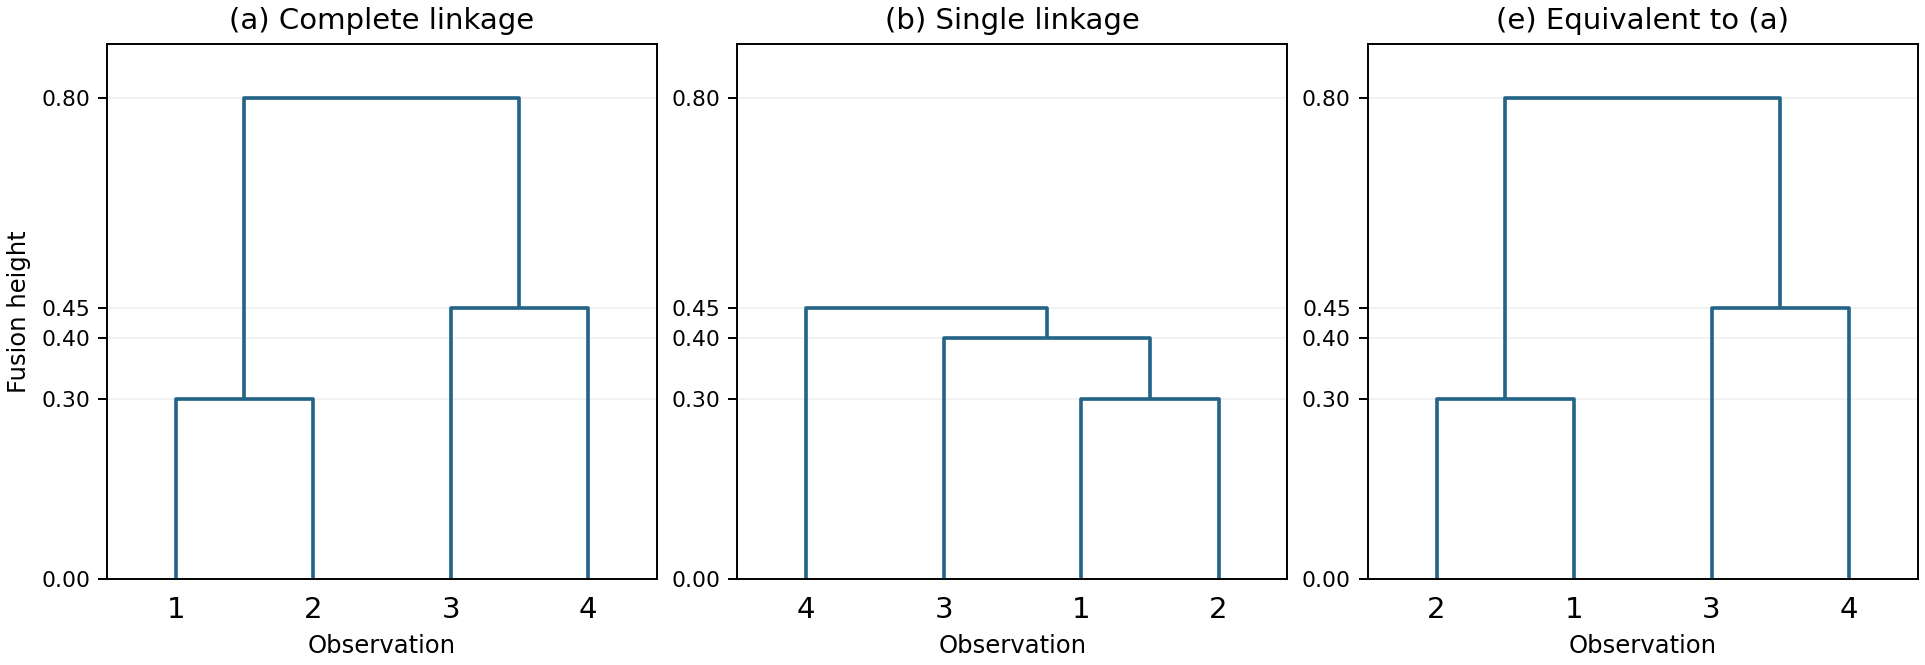

(a)(b) As shown in the diagram

(c) Cutting the complete-linkage dendrogram gives two clusters: \(\{1,2\}\) and \(\{3,4\}\).

(d) Cutting the single-linkage dendrogram gives two clusters: \(\{1,2,3\}\) and \(\{4\}\).

(e) Panel (e) swaps leaves 1 and 2, giving the leaf order 2, 1, 3, 4. The same observations merge at the same heights as in part (a), so the two dendrograms are equivalent.